# 6. Annotation evaluation

This tutorial shows how to assess ALHENA annotations **when independently labeled nuclei are
available**. You will compare predicted classes with known labels, visualize confusions, and explore
what changes when you retain only higher-confidence predictions.

> **This tutorial teaches**
>
> - **Task:** evaluate an annotation result against known labels
> - **Required inputs:** H&E images, nucleus label maps, and independent labels for those nuclei
> - **Outputs:** a `ScoreReport`, a confusion matrix, and a confidence sweep
> - **Example used here:** a small PanNuke Breast sample on the `compartment_v1` axis
> - **Key concept:** performance, prediction confidence, and the fraction of retained cells answer
>   different questions

```text
images + nuclei + reference  →  annotate()  →  predictions
predictions + known labels   →  score()     →  evaluation
```

> **About these example outputs.** This tutorial uses the first 200 Breast fields in PanNuke fold 1,
> in file order. They form a **convenience sample for demonstrating the evaluation workflow**, not a
> representative validation cohort or a benchmark of ALHENA's performance. The resulting scores
> should not be compared directly with results from other cohorts or acquisition settings. No model
> is trained or tuned here.
>
> PanNuke is accessed through the dataset repository and is not redistributed with ALHENA. The
> dataset is licensed under [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/).
> Only aggregate evaluation figures are shown; the original image pixels are not included in the
> tutorial.
>
> Source: Gamper et al., [*PanNuke: An Open Pan-Cancer Histology Dataset for Nuclei Instance Segmentation and Classification*](https://doi.org/10.1007/978-3-030-23937-4_2), ECDP 2019.

This example uses the three broad classes of `compartment_v1`. The PanNuke *Neoplastic* and
*Epithelial* categories are both mapped to `Epithelial_Melanocyte`. This exercise therefore does
**not** evaluate malignancy classification. Nuclei labeled *Dead* are excluded, as in the demo.

In [1]:
import warnings

import alhena
from alhena import demo

# Optional model configuration, as in Tutorial 1.
BACKBONE = None
BUNDLE = None
DEVICE = None

# The labeled example: the first N_FIELDS fields of TISSUE in one PanNuke fold, in file order.
TISSUE = "Breast"
FOLD = 1
N_FIELDS = 200

# Optional local copy of the PanNuke fold file; None reads the fields from the dataset repository.
PARQUET = None

print(alhena.__version__)

0.1.0


## Load images and known labels

`demo.fetch_pannuke()` retrieves the H&E fields, nucleus label maps, and nucleus categories. Here, it
provides **example data**; the subsequent annotation and evaluation use ALHENA's standard Python
API.

The label maps identify individual nuclei. The known categories provide the independent labels
against which predictions will be compared.

In [2]:
with warnings.catch_warnings(record=True) as raised:
    warnings.simplefilter("always")
    cohort = demo.fetch_pannuke(tissue=TISSUE, fold=FOLD, n_tiles=N_FIELDS, parquet=PARQUET)
for entry in raised:
    print(type(entry.message).__name__, entry.message)

print(len(cohort.tiles), cohort.tissue, "fields |", cohort.n_nuclei, "nuclei with a known class |",
      "excluded as Dead:", cohort.n_dead)

GeometryWarning PanNuke declares 0.25 microns per pixel, which is nominal and resampled rather than native optical: fields scanned at 20x were enlarged to 40x by the authors, and the release marks none of them, so they cannot be filtered out. The declared resolution is passed on as it stands.
200 Breast fields | 4621 nuclei with a known class | excluded as Dead: 1


## Annotate the nuclei

`load_celltyper()` selects the prebuilt Breast reference on the broad `compartment_v1` axis. Unlike
the saved-embeddings workflow in Tutorial 3, this example starts directly from image tiles and
nucleus label maps: `annotate()` computes cell embeddings and annotations in one call.

Before annotation, `preflight()` checks how the input geometry fits the encoder. Each PanNuke field
covers a smaller area than the encoder's input field of view, so substantial white padding is
required. The image resolution is nominal, which is a separate consideration when interpreting these
example results.

In [3]:
typer = alhena.load_celltyper(
    tissue=cohort.reference_tissue, axis="compartment_v1",
    backbone=BACKBONE, bundle=BUNDLE, device=DEVICE,
)

geometry = typer.preflight(cohort.images, cohort.label_maps, mpp=demo.PANNUKE_MPP)
print("input image field of view", round(geometry.field_of_view_um, 1), "micron | white pad",
      round(geometry.pad_fraction, 3))
for note in geometry.warnings:
    print(note)

input image field of view 64.0 micron | white pad 0.546


In [4]:
result = typer.annotate(cohort.images, cohort.label_maps, mpp=demo.PANNUKE_MPP)

print(result.axis, result.class_order)
print(len(result), "of", cohort.n_nuclei, "nuclei encoded |", int(result.valid.sum()), "annotated")

compartment_v1 ('Epithelial_Melanocyte', 'Immune', 'Stromal_Vascular')
4590 of 4621 nuclei encoded | 4590 annotated


## Compare predictions with known labels

Predictions and known labels must describe **the same nuclei in the same order**. The PanNuke loader
provides a mapping from nucleus identifiers to known classes. `align_truth()` puts this mapping in
the order of `result.cell_id`, rather than assuming that the two inputs already share the same row
order.

`score()` measures agreement with the known labels. With `macro_min_support=0`, each class
represented among the evaluated nuclei contributes to macro F1.

Not every nucleus with a known label necessarily appears in the annotation result. Nuclei that reach
no image token are excluded during encoding and are therefore not included in the evaluation. Here,
4,590 of the 4,621 labeled nuclei are evaluated. Within that population, a nucleus with no assigned
prediction would count as an error in `score()`.

The report also carries a simple comparison based on the known labels alone: the score obtained by
always predicting the most common class. This **commonest-class baseline** is calculated
independently of ALHENA's predictions. It helps put the evaluation score into context, but it does
not measure generalization.

In [5]:
truth = alhena.align_truth(result, cohort.truth_by_cell())

report = alhena.score(result, truth, macro_min_support=0)

print(report.n_cells, "of", cohort.n_nuclei, "known nuclei evaluated |",
      int(result.valid.sum()), "annotated")
print(f"macro F1 {report.macro_f1:.3f} | commonest-class baseline {report.floor_macro_f1:.3f}")
print(f"accuracy {report.accuracy:.3f} | commonest-class baseline {report.floor_accuracy:.3f}")

4590 of 4621 known nuclei evaluated | 4590 annotated
macro F1 0.788 | commonest-class baseline 0.270
accuracy 0.879 | commonest-class baseline 0.680


These numbers describe agreement with PanNuke labels **on these selected nuclei only**. They are not
an estimate of how ALHENA performs on arbitrary slides. The reference, class mapping, image
resolution, and selection of fields all affect their interpretation.

## Where do predictions disagree?

A single score hides which classes are confused. `viz.confusion()` shows the distribution of
predicted classes for nuclei with each known label. Read **rows as known classes** and **columns as
predicted classes**.

Each row is normalized over nuclei **that received a prediction**. Nuclei with no prediction are
shown separately and count as errors in the overall evaluation. Therefore, a diagonal value is not
necessarily the full recall for that class.

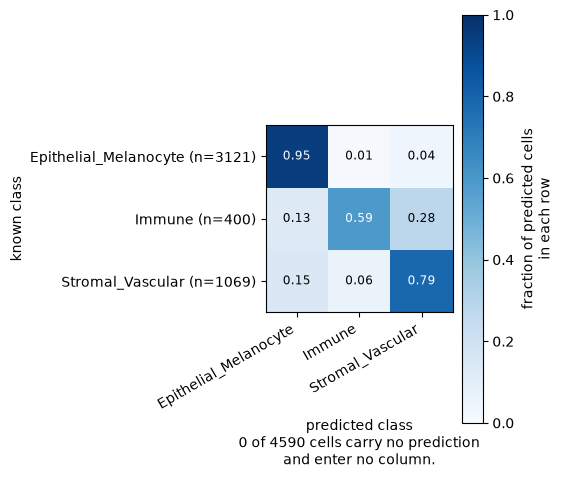

In [6]:
import matplotlib.pyplot as plt

from alhena import viz

viz.confusion(report, missing_classes=typer.reference)
plt.show()

## What changes at higher confidence thresholds?

An annotation's confidence is the share of the weighted neighbor vote assigned to its predicted
class. It is **not** a calibrated probability of being correct.

`confidence_sweep()` repeats the evaluation after retaining only predictions that meet each
confidence threshold. `viz.confidence_curve()` plots the resulting performance together with
class-level recall and the fraction of cells retained.

A better score on the retained cells can come at the cost of excluding more cells. Compare both
curves before choosing a threshold; no single cutoff is guaranteed to work for every dataset.

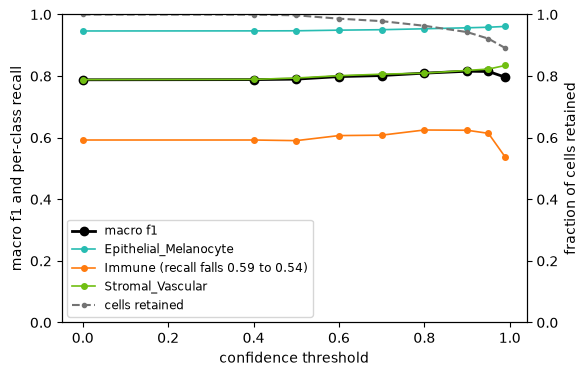

In [7]:
thresholds = [0.0, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99]
sweep = alhena.confidence_sweep(result, truth, thresholds=thresholds)

viz.confidence_curve(sweep, missing_classes=typer.reference)
plt.show()

The plotted metrics apply to the nuclei retained at each threshold, so the evaluated population
changes across the curve. Class-specific recall is calculated on the retained subset. This is a way
to **inspect** a confidence threshold on labeled data, not to select a universal threshold from an
illustrative sample.

## What this tutorial shows

ALHENA separates three questions:

- **What does it predict?** `annotate()` produces cell types and confidence values.
- **How do predictions agree with known labels?** `score()` and `viz.confusion()` summarize
  agreement and class confusions.
- **What happens when uncertain predictions are excluded?** `confidence_sweep()` and
  `viz.confidence_curve()` reveal the performance–coverage tradeoff.

This workflow requires independent labels. Without them, annotation confidence and a colored image
overlay describe the **predictions**, but do not measure their correctness.

For more detail about the interpretation of these metrics, see
[Cell typing](../../concepts/cell-typing/) and [Scoring](../../api/metrics/).

---

**Next:** [Use case example](../../use-case/crc_multiscale/)